In [1]:
import pandas as pd
import numpy as np

import scorecardpy as sc

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

In [2]:
data = pd.read_csv(
    "../data/processed/freddie_processed.csv"
)

print("Shape:", data.shape)

data.head()

Shape: (291451, 24)


/var/folders/92/ptnjnlq917lb_tj60r_31src0000gn/T/ipykernel_99162/1527087970.py:1: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(


,CreditScore,FirstTimeHomebuyer,MSA,MIP,Units,Occupancy,OCLTV,DTI,OrigUPB,LTV,OrigInterestRate,Channel,PPM,ProductType,PropertyState,PropertyType,PostalCode,LoanPurpose,OrigLoanTerm,NumBorrowers,SellerName,ServicerName,EverDelinquent,MonthsInRepayment
0,717.0,N,16974,25,1,O,89,27,117000,89,6.750,T,N,FRM,IL,SF,60400,P,360,2,FL,WASHINGTONMUTUALBANK,0,52
1,717.0,N,19740,0,1,O,73,17,109000,73,6.500,R,N,FRM,CO,SF,80200,N,360,1,FT,CHASEHOMEFINANCELLC,0,144
2,717.0,N,29940,0,1,O,75,16,88000,75,6.875,T,N,FRM,KS,SF,66000,N,360,2,FL,WASHINGTONMUTUALBANK,0,67
3,717.0,N,31084,0,1,O,76,14,160000,76,6.875,R,N,FRM,CA,SF,90700,N,360,2,GM,GMACMTGECORP,0,35
4,717.0,N,35644,0,1,O,78,18,109000,78,7.125,R,N,FRM,NJ,SF,7600,N,360,2,GM,GMACMTGECORP,0,54


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 291451 entries, 0 to 291450
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   CreditScore         291451 non-null  float64
 1   FirstTimeHomebuyer  291451 non-null  object 
 2   MSA                 291451 non-null  object 
 3   MIP                 291451 non-null  int64  
 4   Units               291451 non-null  int64  
 5   Occupancy           291451 non-null  object 
 6   OCLTV               291451 non-null  int64  
 7   DTI                 291451 non-null  int64  
 8   OrigUPB             291451 non-null  int64  
 9   LTV                 291451 non-null  int64  
 10  OrigInterestRate    291451 non-null  float64
 11  Channel             291451 non-null  object 
 12  PPM                 291451 non-null  object 
 13  ProductType         291451 non-null  object 
 14  PropertyState       291451 non-null  object 
 15  PropertyType        291451 non-nul

In [4]:
data["EverDelinquent"].value_counts()

EverDelinquent
0    233788
1     57663
Name: count, dtype: int64

In [5]:
data["EverDelinquent"].value_counts(normalize=True) * 100

EverDelinquent
0    80.215199
1    19.784801
Name: proportion, dtype: float64

In [7]:
target = "EverDelinquent"

print("Target Variable:", target)

Target Variable: EverDelinquent


In [8]:
train, test = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data[target]
)

In [9]:
print("Train Shape:", train.shape)
print("Test Shape :", test.shape)

Train Shape: (204015, 24)
Test Shape : (87436, 24)


In [10]:
train[target].value_counts(normalize=True)

EverDelinquent
0    0.802152
1    0.197848
Name: proportion, dtype: float64

In [11]:
test[target].value_counts(normalize=True)


EverDelinquent
0    0.802152
1    0.197848
Name: proportion, dtype: float64

In [12]:
train.columns

Index(['CreditScore', 'FirstTimeHomebuyer', 'MSA', 'MIP', 'Units', 'Occupancy',
       'OCLTV', 'DTI', 'OrigUPB', 'LTV', 'OrigInterestRate', 'Channel', 'PPM',
       'ProductType', 'PropertyState', 'PropertyType', 'PostalCode',
       'LoanPurpose', 'OrigLoanTerm', 'NumBorrowers', 'SellerName',
       'ServicerName', 'EverDelinquent', 'MonthsInRepayment'],
      dtype='object')

In [13]:
train.nunique().sort_values(ascending=False)

PostalCode            1756
MSA                    391
CreditScore            364
OrigUPB                363
OrigInterestRate       216
MonthsInRepayment      212
OCLTV                  102
LTV                     96
DTI                     66
OrigLoanTerm            61
PropertyState           53
MIP                     32
ServicerName            20
SellerName              20
PropertyType             7
Channel                  4
Units                    4
FirstTimeHomebuyer       3
LoanPurpose              3
NumBorrowers             3
Occupancy                3
PPM                      3
EverDelinquent           2
ProductType              1
dtype: int64

In [14]:
drop_cols = [
    "PostalCode",
    "ProductType"
]

train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)

print(train.shape)
print(test.shape)

(204015, 22)
(87436, 22)


In [15]:
train.isnull().sum()

CreditScore           0
FirstTimeHomebuyer    0
MSA                   0
MIP                   0
Units                 0
Occupancy             0
OCLTV                 0
DTI                   0
OrigUPB               0
LTV                   0
OrigInterestRate      0
Channel               0
PPM                   0
PropertyState         0
PropertyType          0
LoanPurpose           0
OrigLoanTerm          0
NumBorrowers          0
SellerName            0
ServicerName          0
EverDelinquent        0
MonthsInRepayment     0
dtype: int64

In [16]:
bins = sc.woebin(
    train,
    y=target
)

[INFO] creating woe binning ...


/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so each e

>>> There are 2 variables have too many unique non-numberic values, which might cause the binning process slow. Please double check the following variables: 
MSA, PropertyState
>>> Continue the binning process?
1: yes 
2: no


/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  datetime_cols = dat.apply(pd.to_numeric,errors='ignore').select_dtypes(object).apply(pd.to_datetime,errors='ignore').select_dtypes('datetime64').columns.tolist()
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/condition_fun.py:40: UserWarning: Could not 

Binning on 204015 rows and 22 columns in 00:02:47


/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/woebin.py:446: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binning_1bst_brk = binning_1bst_brk.groupby(['variable', 'bstbin'], group_keys=False)\
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/woebin.py:447: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({'good':sum, 'bad':sum, 'bin':lambda x:'%,%'.join(x)}).reset_index()\
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/woebin.py:447: FutureWarning: The provided callable <built-in function sum> is currently using Se

In [17]:
bins.keys()

dict_keys(['MSA', 'FirstTimeHomebuyer', 'MonthsInRepayment', 'OrigUPB', 'PropertyState', 'Units', 'MIP', 'OrigInterestRate', 'PropertyType', 'CreditScore', 'PPM', 'OCLTV', 'OrigLoanTerm', 'ServicerName', 'LTV', 'SellerName', 'DTI', 'Channel', 'LoanPurpose', 'Occupancy', 'NumBorrowers'])

In [18]:
len(bins)

21

In [19]:
"PostalCode" in train.columns

False

In [20]:
iv = sc.iv(
    train,
    y=target
)

iv.sort_values(
    by="info_value",
    ascending=False
)

,variable,info_value
9,CreditScore,0.465652
2,MonthsInRepayment,0.403326
13,ServicerName,0.129679
0,MSA,0.069209
3,OrigUPB,0.046810
4,PropertyState,0.042052
15,SellerName,0.039690
14,LTV,0.035708
11,OCLTV,0.035627
16,DTI,0.033036


In [22]:
selected_features = iv.loc[
    iv["info_value"] >= 0.02,
    "variable"
].tolist()

selected_features

['CreditScore',
 'MonthsInRepayment',
 'ServicerName',
 'MSA',
 'OrigUPB',
 'PropertyState',
 'SellerName',
 'LTV',
 'OCLTV',
 'DTI',
 'NumBorrowers',
 'OrigInterestRate',
 'MIP']

In [24]:
train_woe = sc.woebin_ply(train, bins)
test_woe = sc.woebin_ply(test, bins)

[INFO] converting into woe values ...
[INFO] converting into woe values ...


In [25]:
train_woe.head()

,EverDelinquent,OrigUPB_woe,PropertyState_woe,Units_woe,MIP_woe,OrigInterestRate_woe,PropertyType_woe,PPM_woe,OCLTV_woe,OrigLoanTerm_woe,LoanPurpose_woe,Occupancy_woe,NumBorrowers_woe,MSA_woe,FirstTimeHomebuyer_woe,MonthsInRepayment_woe,CreditScore_woe,ServicerName_woe,LTV_woe,SellerName_woe,DTI_woe,Channel_woe
180345,0,-0.067565,-0.255644,0.0,-0.122732,-0.175388,0.034713,0.0,-0.015568,0.0,-0.060239,0.0,0.226301,-0.138571,0.060208,0.482926,-0.242176,-0.376711,-0.016472,-0.391760,-0.409797,0.047484
75301,1,-0.237572,-0.255644,0.0,-0.122732,-0.175388,0.034713,0.0,-0.173103,0.0,0.097615,0.0,-0.139219,-0.427860,-0.028582,0.482926,0.296145,0.129433,-0.173169,0.388768,0.014548,0.047484
206122,0,-0.067565,-0.102647,0.0,-0.122732,-0.016154,0.034713,0.0,-0.015568,0.0,0.013001,0.0,-0.139219,0.078651,-0.028582,-0.400377,-0.836636,-0.140811,-0.016472,-0.036513,-0.157326,0.047484
160121,0,-0.067565,0.083157,0.0,-0.122732,-0.086285,0.034713,0.0,-0.173103,0.0,0.097615,0.0,-0.139219,-0.138571,-0.028582,-0.400377,-0.242176,-0.140811,-0.173169,0.131738,-0.157326,0.047484
269742,0,-0.067565,-0.102647,0.0,-0.122732,-0.016154,0.034713,0.0,-0.362225,0.0,-0.060239,0.0,-0.139219,-0.138571,-0.028582,-1.255693,-0.836636,-0.376711,-0.362106,-0.036513,0.205231,0.047484


In [26]:
train_woe.shape

(204015, 22)

In [27]:
bins["CreditScore"]

,variable,bin,count,count_distr,good,bad,badprob,woe,bin_iv,total_iv,breaks,is_special_values
0,CreditScore,"[-inf,630.0)",13009,0.063765,7216,5793,0.445307,1.180147,0.117336,0.433594,630.0,False
1,CreditScore,"[630.0,660.0)",22187,0.108752,14103,8084,0.364358,0.843297,0.096220,0.433594,660.0,False
2,CreditScore,"[660.0,700.0)",43171,0.211607,32419,10752,0.249056,0.296145,0.020220,0.433594,700.0,False
3,CreditScore,"[700.0,740.0)",54921,0.269201,46013,8908,0.162197,-0.242176,0.014645,0.433594,740.0,False
4,CreditScore,"[740.0,inf)",70727,0.346675,63900,6827,0.096526,-0.836636,0.185172,0.433594,inf,False


In [28]:
woe_features = [
    col + "_woe"
    for col in selected_features
]

woe_features

['CreditScore_woe',
 'MonthsInRepayment_woe',
 'ServicerName_woe',
 'MSA_woe',
 'OrigUPB_woe',
 'PropertyState_woe',
 'SellerName_woe',
 'LTV_woe',
 'OCLTV_woe',
 'DTI_woe',
 'NumBorrowers_woe',
 'OrigInterestRate_woe',
 'MIP_woe']

In [29]:
X_train = train_woe[woe_features]
y_train = train_woe[target]

X_test = test_woe[woe_features]
y_test = test_woe[target]

In [30]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(204015, 13)
(87436, 13)
(204015,)
(87436,)


In [31]:
from sklearn.linear_model import LogisticRegression

In [32]:
model = LogisticRegression(
    max_iter=1000,
    solver="lbfgs"
)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [34]:
pred_train = model.predict(X_train)

pred_test = model.predict(X_test)

prob_train = model.predict_proba(X_train)[:,1]

prob_test = model.predict_proba(X_test)[:,1]

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [35]:
X_test.isnull().sum()

CreditScore_woe          0
MonthsInRepayment_woe    0
ServicerName_woe         0
MSA_woe                  1
OrigUPB_woe              0
PropertyState_woe        0
SellerName_woe           0
LTV_woe                  0
OCLTV_woe                0
DTI_woe                  0
NumBorrowers_woe         0
OrigInterestRate_woe     0
MIP_woe                  0
dtype: int64

In [36]:
X_test[X_test["MSA_woe"].isnull()]

,CreditScore_woe,MonthsInRepayment_woe,ServicerName_woe,MSA_woe,OrigUPB_woe,PropertyState_woe,SellerName_woe,LTV_woe,OCLTV_woe,DTI_woe,NumBorrowers_woe,OrigInterestRate_woe,MIP_woe
73465,0.296145,-1.255693,-0.140811,NaN,0.362352,0.32305,-0.036513,-0.173169,-0.173103,0.205231,0.226301,-0.016154,-0.122732


In [37]:
X_test = X_test.fillna(0)

In [38]:
pred_train = model.predict(X_train)

pred_test = model.predict(X_test)

prob_train = model.predict_proba(X_train)[:,1]

prob_test = model.predict_proba(X_test)[:,1]

In [39]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [40]:
print("Train Accuracy:",
      accuracy_score(y_train, pred_train))

print("Test Accuracy:",
      accuracy_score(y_test, pred_test))

Train Accuracy: 0.8157978580006372
Test Accuracy: 0.8140239718193879


In [41]:
print("Train AUC:",
      roc_auc_score(y_train, prob_train))

print("Test AUC:",
      roc_auc_score(y_test, prob_test))

Train AUC: 0.7518002512054239
Test AUC: 0.7448423914606186


In [42]:
print(confusion_matrix(y_test, pred_test))

[[67936  2201]
 [14060  3239]]


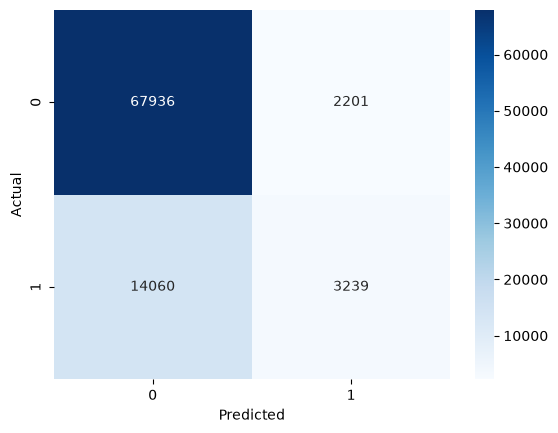

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, pred_test)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [45]:
print(classification_report(y_test, pred_test))

              precision    recall  f1-score   support

           0       0.83      0.97      0.89     70137
           1       0.60      0.19      0.28     17299

    accuracy                           0.81     87436
   macro avg       0.71      0.58      0.59     87436
weighted avg       0.78      0.81      0.77     87436



In [46]:
from scipy.stats import ks_2samp

ks = ks_2samp(
    prob_test[y_test==0],
    prob_test[y_test==1]
)

print(ks.statistic)

0.3643553387300318


### Scorecard Generation


In [ ]:

type(bins)

dict

In [48]:
type(model)

sklearn.linear_model._logistic.LogisticRegression

In [64]:
card = sc.scorecard(
    bins=bins,
    model=model,
    xcolumns=X_train.columns,
    points0=500,
    odds0=20,
    pdo=20
)

In [65]:
card

{'basepoints':      variable  bin  points
 0  basepoints  NaN   627.0,
 'CreditScore':        variable            bin  points
 33  CreditScore   [-inf,630.0)   -34.0
 34  CreditScore  [630.0,660.0)   -24.0
 35  CreditScore  [660.0,700.0)    -8.0
 36  CreditScore  [700.0,740.0)     7.0
 37  CreditScore    [740.0,inf)    24.0,
 'MonthsInRepayment':              variable           bin  points
 8   MonthsInRepayment   [-inf,15.0)    35.0
 9   MonthsInRepayment   [15.0,55.0)    11.0
 10  MonthsInRepayment  [55.0,150.0)   -14.0
 11  MonthsInRepayment   [150.0,inf)   -33.0,
 'ServicerName':         variable                                                bin  points
 44  ServicerName  FIFTHTHIRDBANK      %,%SUNTRUSTMORTGAGEINC%,%F...     2.0
 45  ServicerName  ABNAMROMTGEGROUPINC%,%WELLSFARGOHOMEMORTGA%,%P...     1.0
 46  ServicerName  GMACMTGECORP        %,%CHASEMANHATTANMTGECO%,%...    -1.0
 47  ServicerName  CITIMORTGAGEINC    %,%CHASEHOMEFINANCELLC %,%W...    -5.0,
 'MSA':   variable      

In [66]:
train_score = sc.scorecard_ply(
    train,
    card
)

test_score = sc.scorecard_ply(
    test,
    card
)

/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/scorecard.py:353: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat_score.loc[:,'score'] = card_basepoints + dat_score.sum(axis=1)
/opt/miniconda3/envs/credit_risk_genai/lib/python3.11/site-packages/scorecardpy/scorecard.py:353: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat_score.loc[:,'score'] = card_basepoints + dat_score.sum(axis=1)


In [67]:
test_score.head()

,score
103986,624.0
30381,583.0
25653,630.0
30279,587.0
145660,641.0


In [68]:
test_score.shape

(87436, 1)

In [69]:
test_score.columns

Index(['score'], dtype='object')

In [70]:
card["basepoints"]

,variable,bin,points
0,basepoints,NaN,627.0


### Probability of Default

In [71]:
test_score["PD"] = prob_test

In [72]:
test_score["Actual"] = y_test.values

In [73]:
test_score["RiskBand"] = pd.cut(
    test_score["score"],
    bins=[0,550,650,750,900],
    labels=[
        "High Risk",
        "Medium Risk",
        "Low Risk",
        "Very Low Risk"
    ]
)

In [74]:
test_score.head()

,score,PD,Actual,RiskBand
103986,624.0,0.210437,0,Medium Risk
30381,583.0,0.521656,1,Medium Risk
25653,630.0,0.177745,0,Medium Risk
30279,587.0,0.487582,0,Medium Risk
145660,641.0,0.127592,0,Medium Risk


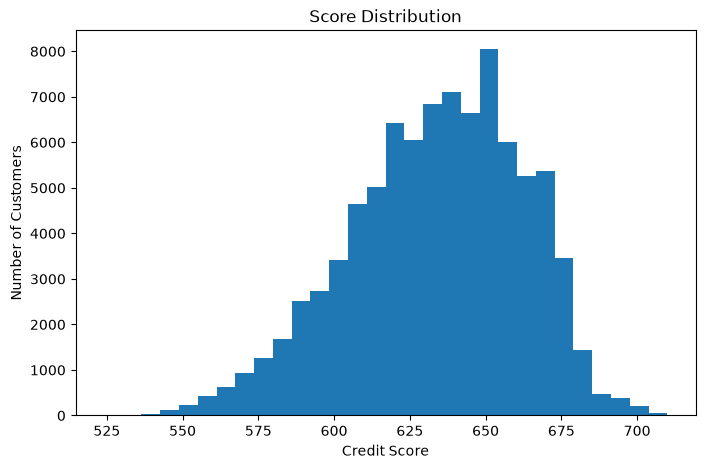

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    test_score["score"],
    bins=30
)

plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.title("Score Distribution")

plt.show()

In [76]:
test_score["RiskBand"].value_counts()

RiskBand
Medium Risk      59907
Low Risk         27299
High Risk          230
Very Low Risk        0
Name: count, dtype: int64

In [77]:
pd.crosstab(
    test_score["RiskBand"],
    test_score["Actual"],
    normalize="index"
)

Actual,0,1
RiskBand,,
High Risk,0.195652,0.804348
Medium Risk,0.745422,0.254578
Low Risk,0.931756,0.068244


In [78]:
import joblib

joblib.dump(model, "../models/logistic_model.pkl")
joblib.dump(card, "../models/scorecard.pkl")

X_train.to_csv("../outputs/X_train.csv")
X_test.to_csv("../outputs/X_test.csv")

y_test.to_csv("../outputs/y_test.csv")

test_score.to_csv(
    "../outputs/customer_scores.csv"
)

In [79]:
joblib.dump(bins, "../models/woe_bins.pkl")

['../models/woe_bins.pkl']